# Análisis integral — Rusty Bargain

## 1. Objetivo, decisión y alcance

Rusty Bargain desarrolla una aplicación para ayudar a personas interesadas en conocer rápidamente el valor de mercado de un coche de segunda mano. El objetivo analítico es estimar `Price` en euros para un perfil de vehículo, equilibrando tres intereses: **calidad de predicción, velocidad de predicción y tiempo de entrenamiento**.

Este único notebook reúne la primera etapa analítica: descripción, diagnóstico de datos, exploración abierta, evaluación predictiva de referencia y escenarios condicionados. No sustituye un pipeline ni una aplicación productiva.

**Preguntas.** ¿Qué representa la fuente y qué tan apta es? ¿Cómo se distribuye el precio? ¿Qué variables se asocian con él? ¿Puede un modelo de referencia superar una baseline en un periodo futuro? ¿Qué escenarios puede mostrar una app sin confundir asociación con causalidad?

**Alcance y límites.** La fuente cubre capturas entre marzo y abril de 2016. Una fila parece ser un perfil/anuncio, no una venta confirmada ni un vehículo con ID estable. El análisis no prueba valor de mercado actual, efectos causales ni el beneficio de reparar un coche. La evaluación predictiva es de referencia; sus criterios de aceptación operativos aún deben acordarse.

## 2. Datos crudos, unidad y diccionario

| Datos crudos | Formato | Uso |
|---|---|---|
| `data/raw/car_data.csv` | CSV | Única fuente analizada; se carga en memoria y no se modifica. |

**Unidad aparente:** perfil/anuncio capturado. No existen VIN, identificador de anuncio o identificador de usuario; los duplicados exactos son sólo una cota inferior de republicaciones.

| Variable | Significado / unidad | Rol y cautela |
|---|---|---|
| `Price` | precio en EUR | target; confirmar si es anuncio, cierre o tasación. |
| `VehicleType`, `Gearbox`, `Model`, `FuelType`, `Brand`, `NotRepaired` | atributos categóricos del vehículo | posibles faltantes y autodeclaración. |
| `RegistrationYear`, `RegistrationMonth` | matriculación | permiten antigüedad si son válidos. |
| `Power` | potencia, CV | revisar ceros y extremos. |
| `Mileage` | kilometraje, km | distribución agrupada por la captura. |
| `DateCrawled`, `DateCreated`, `LastSeen` | fechas de perfil/captura/actividad | `LastSeen` puede filtrar futuro en una cotización inicial. |
| `NumberOfPictures` | número de fotos | se perfila; puede ser constante. |
| `PostalCode` | código postal del perfil | identificador textual, potencialmente sensible; no se geocodifica. |

Nota: No se dispone de metadatos de muestreo, licencia ni definición de precio final. Estos vacíos limitan la representatividad y el uso operativo.

In [1]:
from pathlib import Path
from hashlib import sha256
from time import perf_counter
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

SEED = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 120})

def project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "car_data.csv").is_file():
            return candidate
    raise FileNotFoundError("No se encontró data/raw/car_data.csv desde el directorio de ejecución.")

ROOT = project_root()
DATA_PATH = ROOT / "data" / "raw" / "car_data.csv"
print(f"Ruta: {DATA_PATH.relative_to(ROOT)}")
print(f"SHA256: {sha256(DATA_PATH.read_bytes()).hexdigest()}")

Ruta: data/raw/car_data.csv
SHA256: fbe6fc8bf597d30c26f810e4768244776b65248b9617069e803b42e9515e10b0


## 3. Carga reproducible e inventario

**Pregunta.** ¿Cuál es el esquema y cobertura observados?  
**Procedimiento.** Se leen fechas con formato explícito y códigos postales como texto, preservando ceros iniciales.  
**Resultado e implicación.** Las tablas siguientes identifican los campos disponibles y los rangos temporales reales; no infieren significado adicional al diccionario.

In [2]:
DATE_COLS = ["DateCrawled", "DateCreated", "LastSeen"]
raw = pd.read_csv(DATA_PATH, dtype={"PostalCode": "string"})
for column in DATE_COLS:
    raw[column] = pd.to_datetime(raw[column], format="%d/%m/%Y %H:%M", errors="coerce")

inventory = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "no_nulos": raw.notna().sum(),
    "faltantes": raw.isna().sum(),
    "pct_faltantes": 100 * raw.isna().mean(),
    "distintos": raw.nunique(dropna=True),
}).sort_values("pct_faltantes", ascending=False)
print(f"Filas: {len(raw):,}; columnas: {raw.shape[1]}")
display(inventory)
display(pd.DataFrame({"mínimo": raw[DATE_COLS].min(), "máximo": raw[DATE_COLS].max(), "faltantes": raw[DATE_COLS].isna().sum()}))

Filas: 354,369; columnas: 16


,tipo,no_nulos,faltantes,pct_faltantes,distintos
NotRepaired,str,283215,71154,20.08,2
VehicleType,str,316879,37490,10.58,8
FuelType,str,321474,32895,9.28,7
Gearbox,str,334536,19833,5.60,2
Model,str,334664,19705,5.56,250
Price,int64,354369,0,0.00,3731
RegistrationYear,int64,354369,0,0.00,151
DateCrawled,datetime64[us],354369,0,0.00,15470
Mileage,int64,354369,0,0.00,13
Power,int64,354369,0,0.00,712


,mínimo,máximo,faltantes
DateCrawled,2016-03-05 14:06:00,2016-04-07 14:36:00,0
DateCreated,2014-03-10 00:00:00,2016-04-07 00:00:00,0
LastSeen,2016-03-05 14:15:00,2016-04-07 14:58:00,0


## 4. Diagnóstico de calidad y transformaciones exploratorias

**Pregunta.** ¿Qué problemas pueden sesgar las descripciones o impedir una predicción válida?  
**Procedimiento.** Se auditan duplicados exactos, faltantes, dominios plausibles y coherencia temporal. Sólo los duplicados exactos se excluyen de las vistas analíticas; valores inválidos se marcan y se convierten en ausentes sólo en columnas derivadas de exploración/modelado.  
**Inferencia.** Una bandera no demuestra que el registro sea falso; expone una decisión que debe acordarse antes de operar.

,n
duplicados_exactos,262
precio_no_positivo,10772
año_antes_de_1886,66
año_posterior_a_captura,14530
potencia_no_positiva,40225
potencia_mayor_a_1000,302
mes_fuera_de_1_12,37352
creación_posterior_a_captura,0
última_visita_anterior_a_captura,1


Vista deduplicada: 354,107 filas; precio positivo: 343,337 (97.0%).


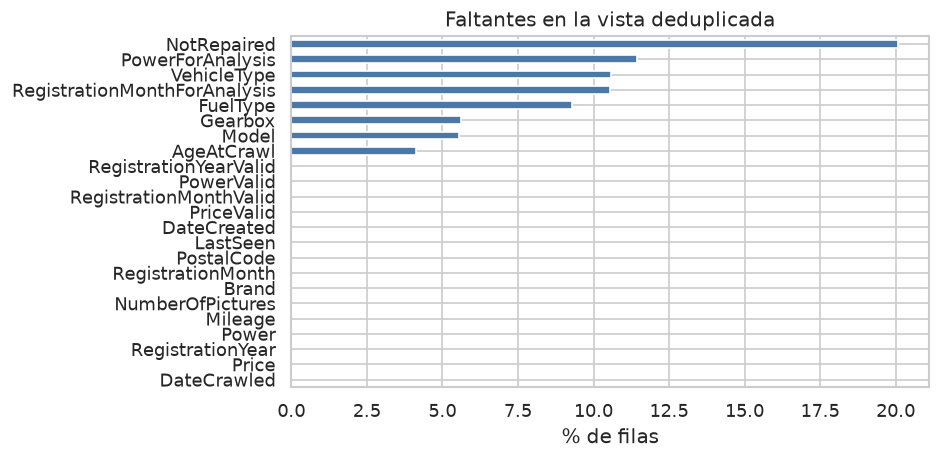

In [3]:
capture_year = raw["DateCrawled"].dt.year
quality = pd.Series({
    "duplicados_exactos": int(raw.duplicated().sum()),
    "precio_no_positivo": int((raw["Price"] <= 0).sum()),
    "año_antes_de_1886": int((raw["RegistrationYear"] < 1886).sum()),
    "año_posterior_a_captura": int((raw["RegistrationYear"] > capture_year).sum()),
    "potencia_no_positiva": int((raw["Power"] <= 0).sum()),
    "potencia_mayor_a_1000": int((raw["Power"] > 1000).sum()),
    "mes_fuera_de_1_12": int((~raw["RegistrationMonth"].between(1, 12)).sum()),
    "creación_posterior_a_captura": int((raw["DateCreated"] > raw["DateCrawled"]).sum()),
    "última_visita_anterior_a_captura": int((raw["LastSeen"] < raw["DateCrawled"]).sum()),
})
display(quality.to_frame("n"))

analysis = raw.drop_duplicates().copy()
analysis["PriceValid"] = analysis["Price"].gt(0)
analysis["RegistrationYearValid"] = analysis["RegistrationYear"].between(1886, analysis["DateCrawled"].dt.year)
analysis["PowerValid"] = analysis["Power"].between(1, 1000)
analysis["RegistrationMonthValid"] = analysis["RegistrationMonth"].between(1, 12)
analysis["AgeAtCrawl"] = (analysis["DateCrawled"].dt.year - analysis["RegistrationYear"]).where(analysis["RegistrationYearValid"])
analysis["PowerForAnalysis"] = analysis["Power"].where(analysis["PowerValid"])
analysis["RegistrationMonthForAnalysis"] = analysis["RegistrationMonth"].where(analysis["RegistrationMonthValid"])
price_positive = analysis.loc[analysis["PriceValid"]].copy()
print(f"Vista deduplicada: {len(analysis):,} filas; precio positivo: {len(price_positive):,} ({len(price_positive)/len(analysis):.1%}).")

fig, ax = plt.subplots(figsize=(8, 4))
(100 * analysis.isna().mean()).sort_values().plot.barh(ax=ax, color="#4C78A8")
ax.set(title="Faltantes en la vista deduplicada", xlabel="% de filas", ylabel="")
plt.tight_layout(); plt.show()

## 5. Preparación y trazabilidad de datos

**Propósito.** Hacer explícitas las vistas y reglas usadas en el análisis integral, sin sobrescribir ni “limpiar” silenciosamente la fuente.  
**Procedimiento.** El contrato lista la regla, el destino, la justificación y el impacto. Las reglas deterministas producen vistas analíticas en memoria; la imputación y codificación aprendidas sólo aparecen dentro de la partición de entrenamiento del bloque predictivo.  
**Límite e implicación.** Los registros cuestionables se marcan, no se declaran automáticamente erróneos. No se realiza enriquecimiento: no hay una fuente externa autorizada, con clave y granularidad validadas.

In [4]:
invalid_year = int((~analysis["RegistrationYearValid"]).sum())
invalid_power = int((~analysis["PowerValid"]).sum())
invalid_month = int((~analysis["RegistrationMonthValid"]).sum())

transformation_contract = pd.DataFrame([
    {"entrada": "toda la fila", "salida / vista": "analysis", "regla": "retirar sólo duplicados exactos", "propósito": "evitar doble conteo en vistas", "impacto": f"{raw.duplicated().sum():,} filas", "etapa": "analítica; determinista"},
    {"entrada": "Price", "salida / vista": "price_positive", "regla": "usar Price > 0 sólo para describir/predicir precio", "propósito": "target con significado operativo", "impacto": f"{(~analysis['PriceValid']).sum():,} filas fuera de esa vista", "etapa": "analítica/predictiva; determinista"},
    {"entrada": "RegistrationYear + DateCrawled", "salida / vista": "AgeAtCrawl", "regla": "año fuera de 1886..año de captura → ausente", "propósito": "evitar antigüedad imposible", "impacto": f"{invalid_year:,} valores marcados", "etapa": "analítica/predictiva; determinista"},
    {"entrada": "Power", "salida / vista": "PowerForAnalysis", "regla": "potencia fuera de 1..1000 → ausente", "propósito": "separar valor cuestionable de potencia usable", "impacto": f"{invalid_power:,} valores marcados", "etapa": "analítica/predictiva; determinista"},
    {"entrada": "RegistrationMonth", "salida / vista": "RegistrationMonthForAnalysis", "regla": "mes fuera de 1..12 → ausente", "propósito": "evitar mes inválido", "impacto": f"{invalid_month:,} valores marcados", "etapa": "analítica/predictiva; determinista"},
    {"entrada": "numéricas/categóricas seleccionadas", "salida / vista": "matriz de entrenamiento", "regla": "mediana/moda y codificación ajustadas sólo con entrenamiento", "propósito": "preparar modelo sin fuga", "impacto": "depende de faltantes por columna", "etapa": "predictiva; aprendida en train"},
    {"entrada": "LastSeen, fechas de perfil, PostalCode, NumberOfPictures", "salida / vista": "features predictivas", "regla": "excluir de la referencia", "propósito": "reducir fuga, ambigüedad temporal, privacidad o constante", "impacto": "4 grupos de variables excluidos", "etapa": "predictiva; decisión de alcance"},
])
display(Markdown("### Contrato de transformaciones"))
for number, row in transformation_contract.iterrows():
    display(Markdown(
        f"#### Regla {number + 1}: `{row['entrada']}` → `{row['salida / vista']}`\n"
        f"- **Regla:** {row['regla']}\n"
        f"- **Propósito:** {row['propósito']}\n"
        f"- **Impacto:** {row['impacto']}\n"
        f"- **Etapa:** {row['etapa']}"
    ))

views = pd.DataFrame([
    {"vista": "raw", "filas": len(raw), "uso": "fuente inmutable y auditoría"},
    {"vista": "analysis", "filas": len(analysis), "uso": "diagnóstico con banderas y derivadas"},
    {"vista": "price_positive", "filas": len(price_positive), "uso": "descripción y modelado de precio positivo"},
    {"vista": "train / test", "filas": "se calcula en sección predictiva", "uso": "transformaciones aprendidas y evaluación temporal"},
])
display(views)
print("No se guardan derivados ni se une información externa. Cualquier enriquecimiento futuro requiere autorización, clave, granularidad, cobertura y validación de fuga.")

### Contrato de transformaciones

#### Regla 1: `toda la fila` → `analysis`
- **Regla:** retirar sólo duplicados exactos
- **Propósito:** evitar doble conteo en vistas
- **Impacto:** 262 filas
- **Etapa:** analítica; determinista

#### Regla 2: `Price` → `price_positive`
- **Regla:** usar Price > 0 sólo para describir/predicir precio
- **Propósito:** target con significado operativo
- **Impacto:** 10,770 filas fuera de esa vista
- **Etapa:** analítica/predictiva; determinista

#### Regla 3: `RegistrationYear + DateCrawled` → `AgeAtCrawl`
- **Regla:** año fuera de 1886..año de captura → ausente
- **Propósito:** evitar antigüedad imposible
- **Impacto:** 14,595 valores marcados
- **Etapa:** analítica/predictiva; determinista

#### Regla 4: `Power` → `PowerForAnalysis`
- **Regla:** potencia fuera de 1..1000 → ausente
- **Propósito:** separar valor cuestionable de potencia usable
- **Impacto:** 40,520 valores marcados
- **Etapa:** analítica/predictiva; determinista

#### Regla 5: `RegistrationMonth` → `RegistrationMonthForAnalysis`
- **Regla:** mes fuera de 1..12 → ausente
- **Propósito:** evitar mes inválido
- **Impacto:** 37,347 valores marcados
- **Etapa:** analítica/predictiva; determinista

#### Regla 6: `numéricas/categóricas seleccionadas` → `matriz de entrenamiento`
- **Regla:** mediana/moda y codificación ajustadas sólo con entrenamiento
- **Propósito:** preparar modelo sin fuga
- **Impacto:** depende de faltantes por columna
- **Etapa:** predictiva; aprendida en train

#### Regla 7: `LastSeen, fechas de perfil, PostalCode, NumberOfPictures` → `features predictivas`
- **Regla:** excluir de la referencia
- **Propósito:** reducir fuga, ambigüedad temporal, privacidad o constante
- **Impacto:** 4 grupos de variables excluidos
- **Etapa:** predictiva; decisión de alcance

,vista,filas,uso
0,raw,354369,fuente inmutable y auditoría
1,analysis,354107,diagnóstico con banderas y derivadas
2,price_positive,343337,descripción y modelado de precio positivo
3,train / test,se calcula en sección predictiva,transformaciones aprendidas y evaluación temporal


No se guardan derivados ni se une información externa. Cualquier enriquecimiento futuro requiere autorización, clave, granularidad, cobertura y validación de fuga.


## 6. Análisis descriptivo

**Pregunta.** ¿Cuál es el nivel, dispersión y composición del precio registrado?  
**Procedimiento.** Se usan medidas robustas y visualizaciones sobre precios positivos, mostrando explícitamente la cobertura.  
**Inferencia.** La asimetría y los topes observados describen la captura; no demuestran una distribución de mercado ni justifican eliminar extremos.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,IQR,asimetría
Price,"343,337.00","4,554.97","4,515.25",1.00,100.00,350.00,"1,200.00","2,890.00","6,500.00","14,800.00","18,850.00","20,000.00","5,300.00",1.41
Mileage,"343,337.00","128,338.35","37,521.99","5,000.00","5,000.00","40,000.00","125,000.00","150,000.00","150,000.00","150,000.00","150,000.00","150,000.00","25,000.00",-1.71
AgeAtCrawl,"329,506.00",13.41,6.93,0.00,0.00,3.00,9.00,13.00,17.00,24.00,36.00,106.00,8.00,1.61
PowerForAnalysis,"306,697.00",120.37,54.85,1.00,45.00,54.00,75.00,110.00,150.00,224.00,305.00,"1,000.00",75.00,1.77


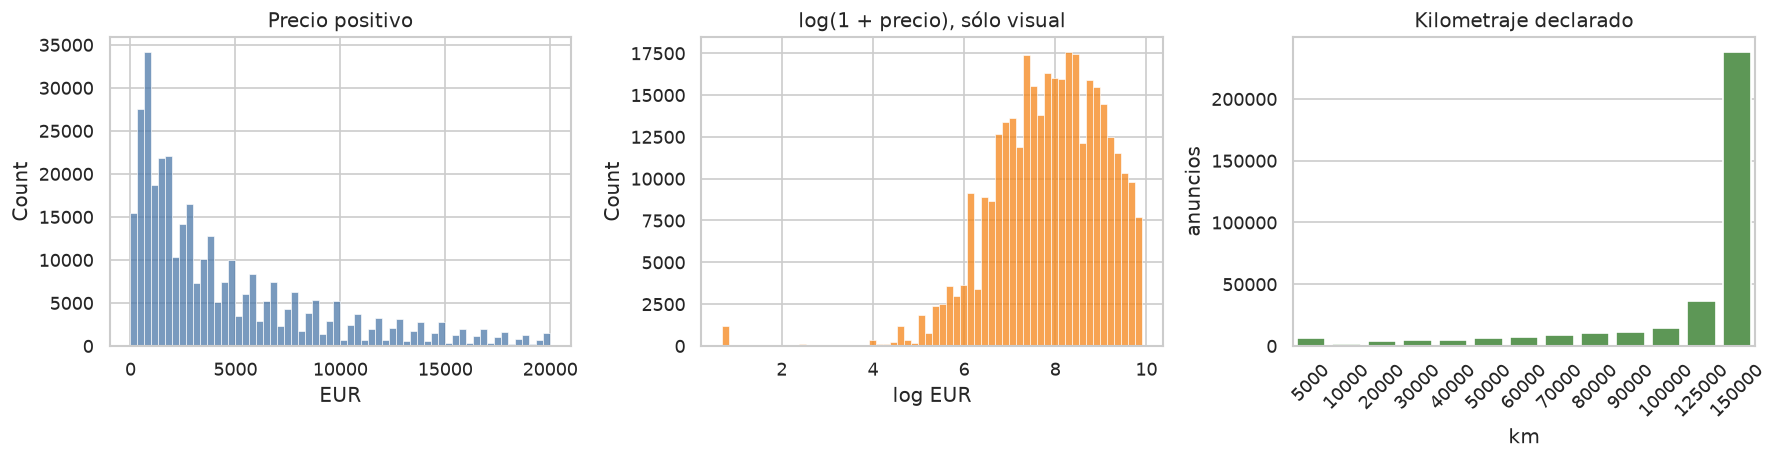

In [5]:
summary = price_positive[["Price", "Mileage", "AgeAtCrawl", "PowerForAnalysis"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T
summary["IQR"] = summary["75%"] - summary["25%"]
summary["asimetría"] = price_positive[["Price", "Mileage", "AgeAtCrawl", "PowerForAnalysis"]].skew()
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(price_positive["Price"], bins=60, color="#4C78A8", ax=axes[0]); axes[0].set(title="Precio positivo", xlabel="EUR")
sns.histplot(np.log1p(price_positive["Price"]), bins=60, color="#F58518", ax=axes[1]); axes[1].set(title="log(1 + precio), sólo visual", xlabel="log EUR")
sns.countplot(data=analysis, x="Mileage", order=sorted(analysis["Mileage"].unique()), color="#54A24B", ax=axes[2])
axes[2].tick_params(axis="x", rotation=45); axes[2].set(title="Kilometraje declarado", xlabel="km", ylabel="anuncios")
plt.tight_layout(); plt.show()

## 7. Segmentos, relaciones y tiempo

**Pregunta.** ¿Qué diferencias descriptivas y asociaciones son relevantes para una tasación?  
**Procedimiento.** Se comparan medianas junto con tamaños de muestra y correlaciones Pearson/Spearman con casos completos. La evolución se agrega por día de captura.  
**Inferencia.** Diferencias entre segmentos y correlaciones no son efectos causales: marca, antigüedad, kilometraje y atributos no observados pueden confundirlas.

,n,mediana,media
Brand,,,
porsche,734,"11,999.00","11,354.17"
mini,3164,"8,299.00","9,098.91"
land_rover,534,"7,300.00","8,603.00"
jeep,658,"6,000.00","7,269.10"
bmw,35776,"4,999.00","6,353.08"
dacia,888,"4,900.00","5,906.24"
audi,28557,"4,900.00","6,431.09"
skoda,5425,"4,850.00","5,980.55"
mercedes_benz,31338,"4,449.50","6,039.95"


,n,mediana,media
VehicleType,,,
suv,11786,"8,599.00","9,166.12"
convertible,19842,"5,500.00","6,922.66"
bus,28322,"4,300.00","5,569.59"
coupe,15620,"4,100.00","6,212.82"
wagon,63651,"3,300.00","4,992.52"
sedan,89347,"3,000.00","4,831.28"
other,3084,"2,450.00","3,796.40"
small,77940,"1,599.00","2,739.50"
NaN,33745,"1,400.00","2,638.86"


,n,mediana,media
NotRepaired,,,
no,243449,"3,790.00","5,372.70"
NaN,65858,"1,500.00","2,837.36"
yes,34030,999.00,"2,029.05"


,Price,AgeAtCrawl,PowerForAnalysis,Mileage
Price,1.00,-0.63,0.52,-0.33
AgeAtCrawl,-0.63,1.00,-0.19,0.34
PowerForAnalysis,0.52,-0.19,1.00,0.12
Mileage,-0.33,0.34,0.12,1.00


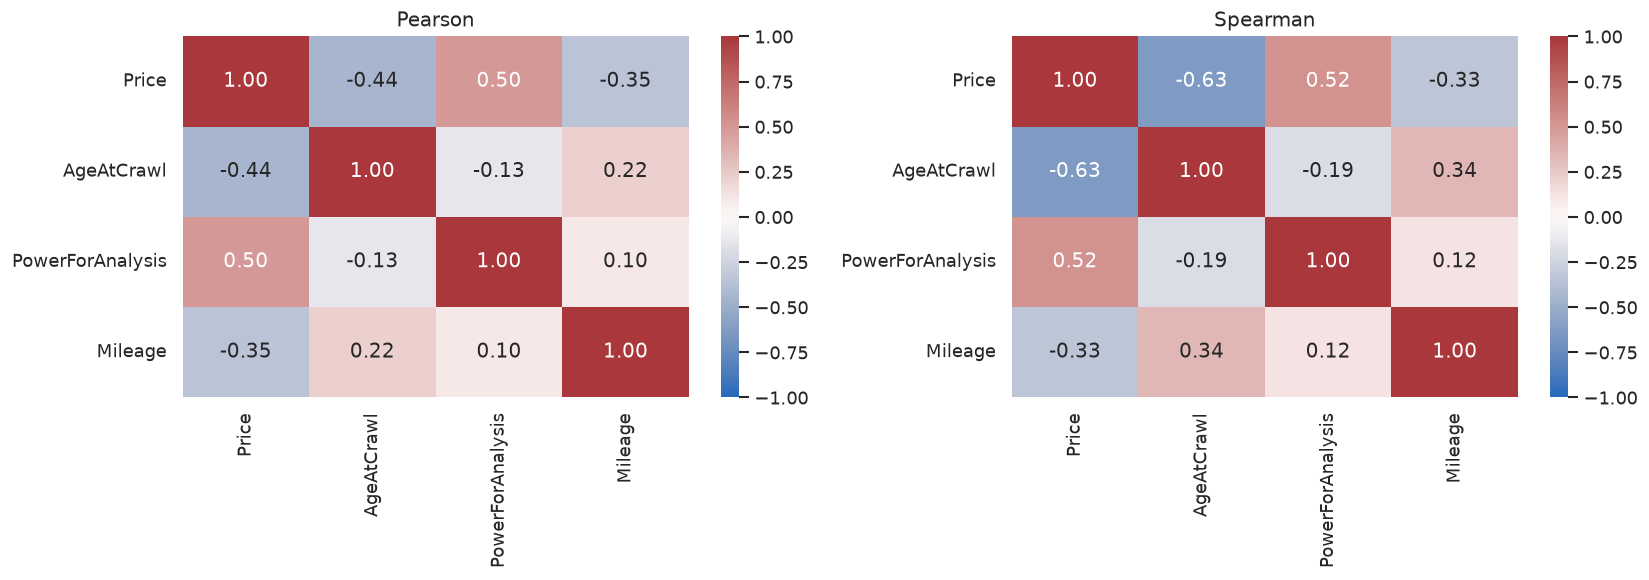

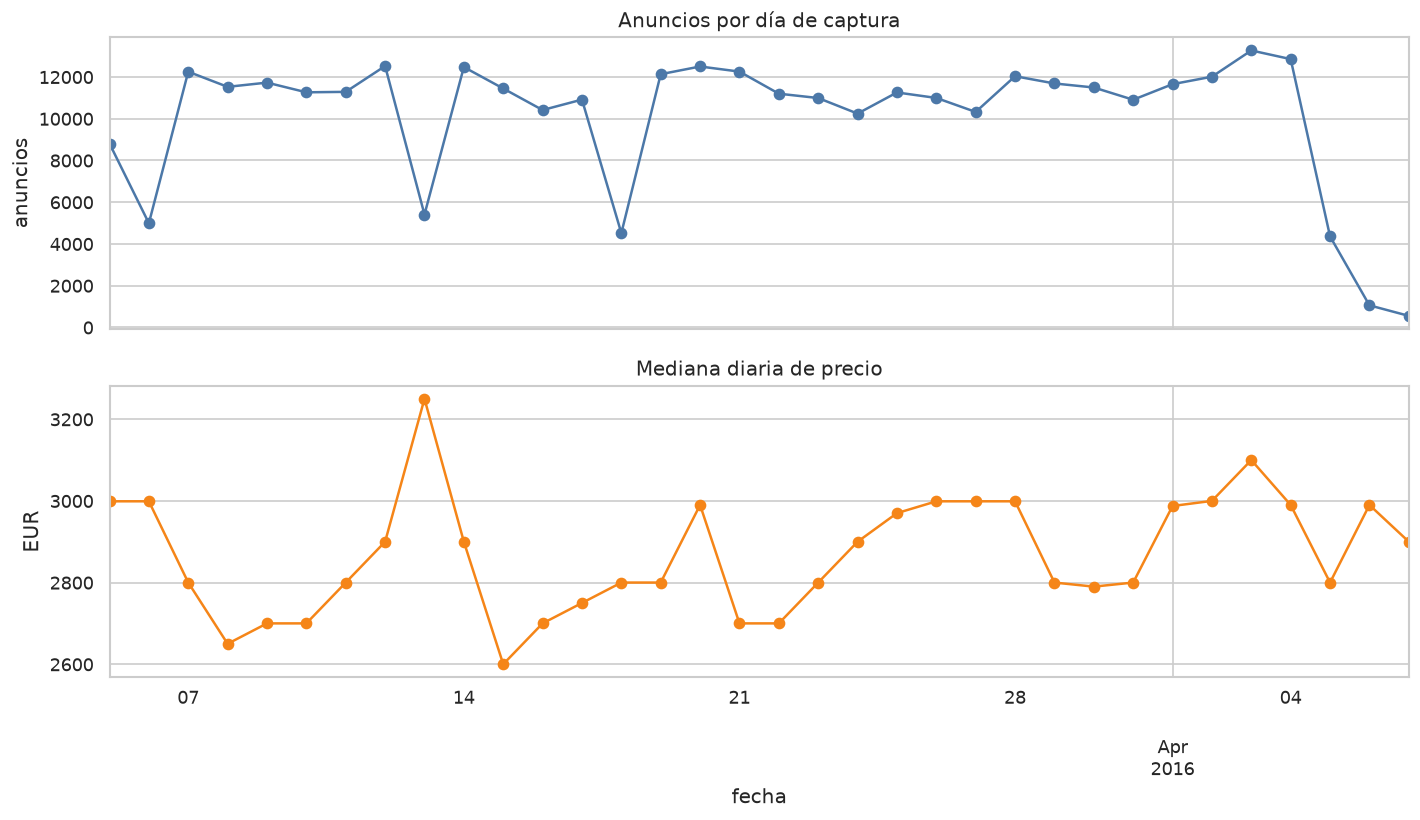

In [6]:
def segment_summary(column, minimum=500):
    return (price_positive.groupby(column, dropna=False)["Price"].agg(n="size", mediana="median", media="mean")
            .query("n >= @minimum").sort_values("mediana", ascending=False))

brand_summary = segment_summary("Brand")
vehicle_summary = segment_summary("VehicleType")
repair_summary = price_positive.groupby("NotRepaired", dropna=False)["Price"].agg(n="size", mediana="median", media="mean").sort_values("mediana", ascending=False)
display(brand_summary); display(vehicle_summary); display(repair_summary)

relations = price_positive[["Price", "AgeAtCrawl", "PowerForAnalysis", "Mileage"]]
display(relations.corr(method="spearman"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(relations.corr(method="pearson"), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(relations.corr(method="spearman"), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout(); plt.show()

daily = (price_positive.assign(CrawlDay=price_positive["DateCrawled"].dt.normalize())
         .groupby("CrawlDay")["Price"].agg(anuncios="size", mediana="median"))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
daily["anuncios"].plot(ax=axes[0], marker="o", color="#4C78A8"); axes[0].set(title="Anuncios por día de captura", ylabel="anuncios")
daily["mediana"].plot(ax=axes[1], marker="o", color="#F58518"); axes[1].set(title="Mediana diaria de precio", ylabel="EUR", xlabel="fecha")
plt.tight_layout(); plt.show()

## 8. Exploración abierta y descubrimiento de patrones

**Propósito.** Ampliar el conocimiento del conjunto más allá de la tasación inmediata, buscando estructuras, concentraciones, relaciones no lineales, interacciones, rarezas y estabilidad temporal que puedan originar hipótesis de producto o de calidad.

**Procedimiento.** Se revisan colas de categorías, bandas interpretables de variables numéricas, patrones de faltantes por precio, una interacción de marca y antigüedad, y la antigüedad del perfil al momento de captura. Todas las tablas enseñan tamaños de grupo; las celdas con poca cobertura se ocultan.  
**Límite.** Esta búsqueda es exploratoria: un patrón puede ser efecto de la captura, de variables no observadas o de múltiples comparaciones. Se documenta como descripción o hipótesis, nunca como causalidad.

,categorías_observadas,faltantes,categoría_más_frecuente,pct_categoría_más_frecuente,categorías_con_≤10_filas,categorías_con_≤100_filas
variable,,,,,,
VehicleType,8,37484,sedan,25.81,0,0
Gearbox,2,19830,manual,75.69,0,0
FuelType,7,32889,petrol,61.04,0,1
Brand,40,0,volkswagen,21.73,0,0
Model,250,19701,golf,8.25,7,44
NotRepaired,2,71145,no,69.73,0,0


Modelos: 250; con ≤10 perfiles: 7; con ≤100 perfiles: 44.
Interpretación: la cola larga de categorías puede requerir una política de categorías raras dentro de entrenamiento; no se agrupa aquí para preservar el diagnóstico.


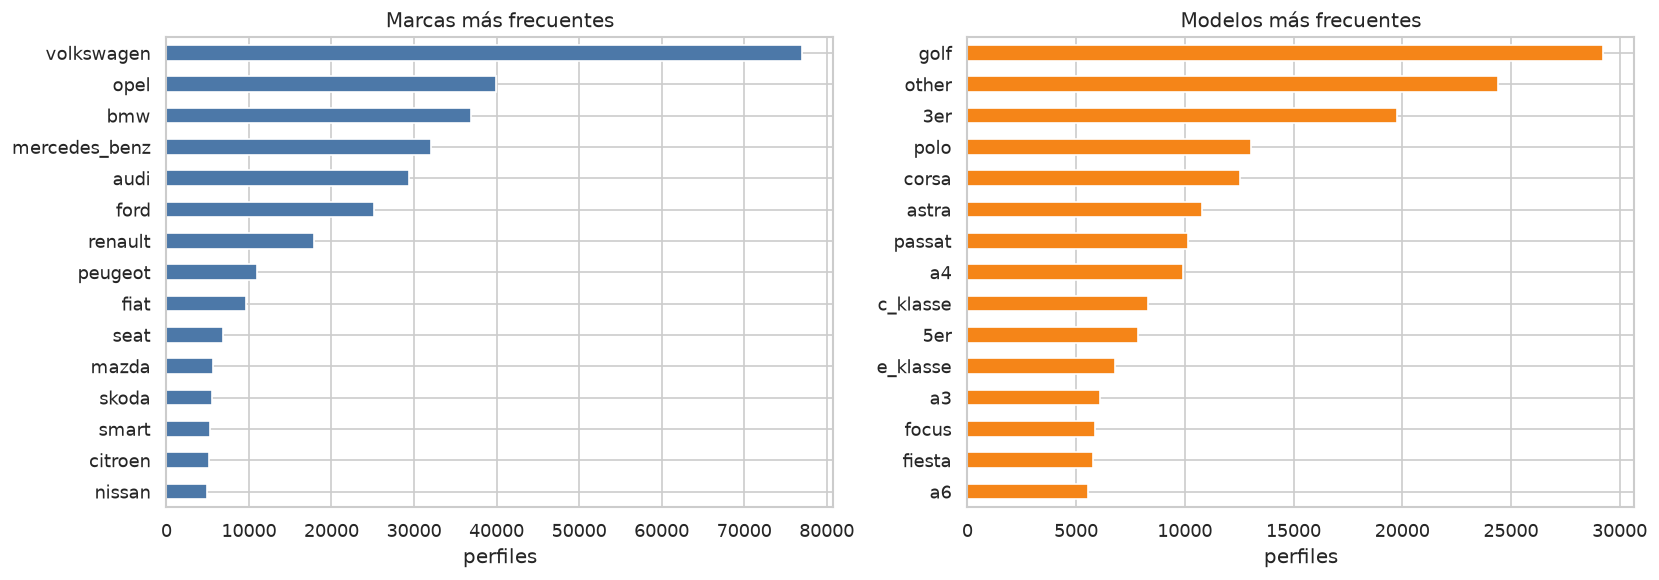

In [7]:
category_columns = ["VehicleType", "Gearbox", "FuelType", "Brand", "Model", "NotRepaired"]
category_profile_rows = []
for column in category_columns:
    counts = analysis[column].value_counts(dropna=False)
    category_profile_rows.append({
        "variable": column,
        "categorías_observadas": analysis[column].nunique(dropna=True),
        "faltantes": int(analysis[column].isna().sum()),
        "categoría_más_frecuente": str(counts.index[0]),
        "pct_categoría_más_frecuente": 100 * counts.iloc[0] / len(analysis),
        "categorías_con_≤10_filas": int((counts <= 10).sum()),
        "categorías_con_≤100_filas": int((counts <= 100).sum()),
    })
category_profile = pd.DataFrame(category_profile_rows).set_index("variable")
display(category_profile)

model_counts = analysis["Model"].value_counts(dropna=True)
print(f"Modelos: {len(model_counts):,}; con ≤10 perfiles: {(model_counts <= 10).sum():,}; con ≤100 perfiles: {(model_counts <= 100).sum():,}.")
print("Interpretación: la cola larga de categorías puede requerir una política de categorías raras dentro de entrenamiento; no se agrupa aquí para preservar el diagnóstico.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
analysis["Brand"].value_counts().head(15).sort_values().plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set(title="Marcas más frecuentes", xlabel="perfiles", ylabel="")
model_counts.head(15).sort_values().plot.barh(ax=axes[1], color="#F58518")
axes[1].set(title="Modelos más frecuentes", xlabel="perfiles", ylabel="")
plt.tight_layout(); plt.show()

,n,mediana,media
AgeBand,,,
"(-1.001, 3.0]",16803,"5,100.00","7,123.62"
"(3.0, 7.0]",42003,"9,800.00","10,304.99"
"(7.0, 12.0]",92732,"5,190.00","6,128.28"
"(12.0, 18.0]",120020,"1,650.00","2,291.74"
"(18.0, 25.0]",46625,899.00,"1,507.30"
"(25.0, inf]",11323,"2,850.00","4,577.91"


,n,mediana,media
MileageBand,,,
"(-0.001, 50000.0]",25676,"7,500.00","8,093.83"
"(50000.0, 100000.0]",51558,"5,999.00","7,165.42"
"(100000.0, 125000.0]",35732,"3,700.00","5,206.18"
"(125000.0, 150000.0]",230371,"2,150.00","3,475.31"


,n,mediana,media
PowerBand,,,
"(-0.001, 60.0]",38312,999.00,"1,568.31"
"(60.0, 90.0]",66609,"1,999.00","2,977.61"
"(90.0, 120.0]",72143,"2,900.00","4,113.93"
"(120.0, 160.0]",70485,"4,450.00","5,847.34"
"(160.0, 220.0]",43674,"6,900.00","7,797.77"
"(220.0, inf]",15474,"10,850.00","10,838.36"


,VehicleType,Gearbox,Model,FuelType,NotRepaired
PriceBand,,,,,
"(-0.001, 1000.0]",18.40,9.80,8.40,16.60,32.80
"(1000.0, 5000.0]",9.30,4.80,4.70,7.80,19.00
"(5000.0, 10000.0]",5.40,2.40,3.40,4.60,11.30
"(10000.0, inf]",3.40,1.60,3.10,3.10,7.50


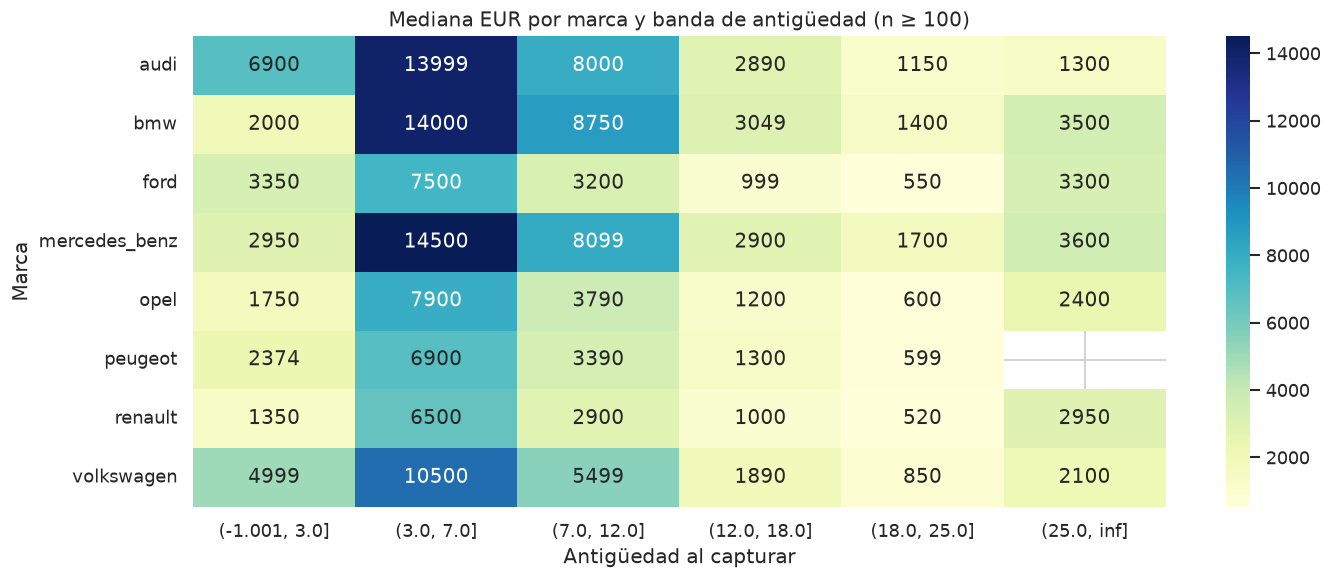

Hipótesis abierta: la forma precio-antigüedad no es idéntica para todas las marcas. Es una asociación descriptiva que debe confirmarse en otro periodo antes de usarla como regla de producto.


In [8]:
discovery = price_positive.assign(
    AgeBand=pd.cut(price_positive["AgeAtCrawl"], [-1, 3, 7, 12, 18, 25, np.inf], include_lowest=True),
    MileageBand=pd.cut(price_positive["Mileage"], [0, 50_000, 100_000, 125_000, 150_000, np.inf], include_lowest=True),
    PowerBand=pd.cut(price_positive["PowerForAnalysis"], [0, 60, 90, 120, 160, 220, np.inf], include_lowest=True),
    PriceBand=pd.cut(price_positive["Price"], [0, 1_000, 5_000, 10_000, np.inf], include_lowest=True),
)

def band_summary(column, minimum=100):
    table = discovery.groupby(column, observed=True)["Price"].agg(n="size", mediana="median", media="mean")
    return table.loc[table["n"] >= minimum]

display(band_summary("AgeBand"))
display(band_summary("MileageBand"))
display(band_summary("PowerBand"))

missing_by_price = (discovery.groupby("PriceBand", observed=True)[["VehicleType", "Gearbox", "Model", "FuelType", "NotRepaired"]]
                    .agg(lambda series: 100 * series.isna().mean()).round(1))
display(missing_by_price)

top_brands = discovery["Brand"].value_counts().head(8).index
brand_age = (discovery.loc[discovery["Brand"].isin(top_brands)]
             .groupby(["Brand", "AgeBand"], observed=True)["Price"].agg(n="size", mediana="median"))
brand_age_grid = brand_age["mediana"].where(brand_age["n"] >= 100).unstack()
plt.figure(figsize=(12, 5))
sns.heatmap(brand_age_grid, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Mediana EUR por marca y banda de antigüedad (n ≥ 100)")
plt.xlabel("Antigüedad al capturar"); plt.ylabel("Marca")
plt.tight_layout(); plt.show()
print("Hipótesis abierta: la forma precio-antigüedad no es idéntica para todas las marcas. Es una asociación descriptiva que debe confirmarse en otro periodo antes de usarla como regla de producto.")

In [9]:
profile_age_days = (analysis["DateCrawled"].dt.normalize() - analysis["DateCreated"].dt.normalize()).dt.days
profile_age = analysis.assign(
    ProfileAgeDays=profile_age_days,
    ProfileAgeBand=pd.cut(profile_age_days, [-1, 0, 7, 30, 90, 365, np.inf], include_lowest=True),
).loc[analysis["PriceValid"]]
profile_age_summary = profile_age.groupby("ProfileAgeBand", observed=True)["Price"].agg(n="size", mediana="median", media="mean")
display(profile_age_summary)
display(profile_age["ProfileAgeDays"].describe(percentiles=[.01, .5, .95, .99]).to_frame("días creación a captura"))

rounded_patterns = pd.Series({
    "pct_mileage_150000": 100 * analysis["Mileage"].eq(150_000).mean(),
    "pct_price_20000_entre_positivos": 100 * price_positive["Price"].eq(20_000).mean(),
    "pct_price_múltiplo_100_entre_positivos": 100 * price_positive["Price"].mod(100).eq(0).mean(),
})
display(rounded_patterns.to_frame("porcentaje"))
print("Hallazgo de calidad: concentraciones o redondeos pueden reflejar interfaces de captura, convenciones de publicación o comportamiento de vendedores; no se clasifican automáticamente como errores.")

,n,mediana,media
ProfileAgeBand,,,
"(-1.001, 0.0]",331927,"2,850.00","4,539.02"
"(0.0, 7.0]",10827,"3,300.00","4,930.49"
"(7.0, 30.0]",402,"5,600.00","6,601.04"
"(30.0, 90.0]",157,"5,999.00","6,974.48"
"(90.0, 365.0]",22,"5,449.50","5,556.14"
"(365.0, inf]",2,"7,499.50","7,499.50"


,días creación a captura
count,"343,337.00"
mean,0.09
std,2.17
min,0.00
1%,0.00
50%,0.00
95%,0.00
99%,1.00
max,737.00


,porcentaje
pct_mileage_150000,67.22
pct_price_20000_entre_positivos,0.08
pct_price_múltiplo_100_entre_positivos,52.59


Hallazgo de calidad: concentraciones o redondeos pueden reflejar interfaces de captura, convenciones de publicación o comportamiento de vendedores; no se clasifican automáticamente como errores.


## 9. Contrato predictivo y diseño de evaluación

**Pregunta.** ¿Se puede realizar una prueba predictiva honesta y útil como referencia?  
**Procedimiento.** Se predice el precio positivo de perfiles futuros usando sólo atributos del vehículo disponibles en la tabla. Se reserva el último 20% de días de captura como prueba temporal. La baseline es la mediana de entrenamiento. Se excluyen `LastSeen`, fechas de perfil, `PostalCode` y `NumberOfPictures`: el primero tiene riesgo de fuga, las fechas no son atributos estables de un coche, el código postal requiere una política de privacidad/uso y la última variable es constante.

**Límite.** No hay ID estable para purgar republicaciones entre periodos. Por ello, las métricas son una referencia, no una estimación definitiva de producción. `Price` continúa siendo precio registrado, no precio final confirmado.

In [10]:
numeric_features = ["AgeAtCrawl", "PowerForAnalysis", "Mileage", "RegistrationMonthForAnalysis"]
categorical_features = ["VehicleType", "Gearbox", "Model", "FuelType", "Brand", "NotRepaired"]
model_features = numeric_features + categorical_features
model_data = price_positive.sort_values("DateCrawled").copy()
model_data = model_data.dropna(subset=["DateCrawled"])
days = np.sort(model_data["DateCrawled"].dt.normalize().unique())
cut = int(len(days) * 0.8)
cutoff = days[cut]
train = model_data.loc[model_data["DateCrawled"].dt.normalize() < cutoff].copy()
test = model_data.loc[model_data["DateCrawled"].dt.normalize() >= cutoff].copy()
X_train, y_train = train[model_features], train["Price"]
X_test, y_test = test[model_features], test["Price"]
print(f"Partición temporal: entrenamiento {train['DateCrawled'].min().date()} a {train['DateCrawled'].max().date()} ({len(train):,}); prueba {test['DateCrawled'].min().date()} a {test['DateCrawled'].max().date()} ({len(test):,}).")
print(f"Días: entrenamiento {train['DateCrawled'].dt.normalize().nunique()}; prueba {test['DateCrawled'].dt.normalize().nunique()}.")

Partición temporal: entrenamiento 2016-03-05 a 2016-03-31 (287,578); prueba 2016-04-01 a 2016-04-07 (55,759).
Días: entrenamiento 27; prueba 7.


## 10. Evaluación predictiva de referencia

**Pregunta.** ¿El modelo de referencia mejora una predicción constante y qué coste temporal tiene?  
**Procedimiento.** Un modelo HistGradientBoosting procesa variables numéricas imputadas por mediana y categorías codificadas dentro de entrenamiento. Se compara contra la mediana de entrenamiento con MAE y RMSE en EUR; se cronometra el ajuste y la predicción de la prueba.  
**Inferencia.** Mejorar una baseline en esta prueba temporal es evidencia predictiva limitada a esta captura. No establece la calidad futura, equidad, ni cumplimiento de una latencia que aún no tiene umbral de negocio.

In [11]:
numeric_pipeline = SimpleImputer(strategy="median", add_indicator=True)
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], verbose_feature_names_out=False)

preprocess_start = perf_counter()
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)
preprocess_seconds = perf_counter() - preprocess_start
categorical_mask = np.array([False] * (X_train_ready.shape[1] - len(categorical_features)) + [True] * len(categorical_features))

baseline_pred = np.full(len(y_test), y_train.median())
model = HistGradientBoostingRegressor(
    learning_rate=0.1, max_iter=200, max_leaf_nodes=31, l2_regularization=1.0,
    early_stopping=True, validation_fraction=0.1, categorical_features=categorical_mask,
    random_state=SEED,
)
fit_start = perf_counter()
model.fit(X_train_ready, y_train)
fit_seconds = perf_counter() - fit_start
predict_start = perf_counter()
model_pred = model.predict(X_test_ready)
predict_seconds = perf_counter() - predict_start

evaluation = pd.DataFrame([
    {"método": "Mediana de entrenamiento", "MAE_EUR": mean_absolute_error(y_test, baseline_pred), "RMSE_EUR": root_mean_squared_error(y_test, baseline_pred), "entrenamiento_s": 0.0, "predicción_prueba_s": 0.0},
    {"método": "HistGradientBoosting", "MAE_EUR": mean_absolute_error(y_test, model_pred), "RMSE_EUR": root_mean_squared_error(y_test, model_pred), "entrenamiento_s": fit_seconds + preprocess_seconds, "predicción_prueba_s": predict_seconds},
])
evaluation["microsegundos_por_predicción_prueba"] = 1_000_000 * evaluation["predicción_prueba_s"] / len(y_test)
display(evaluation)
print(f"Prueba: {len(y_test):,} perfiles. El tiempo de predicción es por lote local; no equivale a latencia de una API ni incluye red/serialización.")

,método,MAE_EUR,RMSE_EUR,entrenamiento_s,predicción_prueba_s,microsegundos_por_predicción_prueba
0,Mediana de entrenamiento,"3,366.42","4,973.11",0.00,0.00,0.00
1,HistGradientBoosting,"1,050.73","1,679.15",1.42,0.08,1.49


Prueba: 55,759 perfiles. El tiempo de predicción es por lote local; no equivale a latencia de una API ni incluye red/serialización.


## 11. Diagnóstico del modelo e incertidumbre por segmentos

**Pregunta.** ¿Dónde se concentra el error y es consistente entre segmentos relevantes?  
**Procedimiento.** Se calcula el error absoluto en la prueba temporal y se agrupa por bandas de precio, marca y estado de reparación, ocultando grupos pequeños.  
**Inferencia.** Las diferencias de error muestran cobertura del modelo en esta muestra; no prueban imparcialidad, causalidad ni fiabilidad fuera del periodo observado.

,n,MAE_EUR,sesgo_EUR
PriceBand,,,
"(10000.0, inf]",7448,"2,201.04","-1,623.08"
"(5000.0, 10000.0]",11313,"1,374.83",-303.71
"(1000.0, 5000.0]",25239,773.35,120.89
"(-0.001, 1000.0]",11759,605.68,517.12


,n,MAE_EUR,sesgo_EUR
NotRepaired,,,
no,39957,"1,090.80",-206.08
NaN,10470,"1,030.16",201.73
yes,5332,790.82,-50.71


,n,MAE_EUR,sesgo_EUR
Brand,,,
sonstige_autos,486,"2,436.77",-2.53
mercedes_benz,5168,"1,414.84",-153.75
bmw,5837,"1,394.66",-210.13
audi,4596,"1,350.95",-130.90
mini,537,"1,334.93",-266.42
volvo,489,"1,187.08",-248.42
volkswagen,12101,"1,060.85",-124.57
alfa_romeo,357,"1,039.15",-104.08
toyota,785,"1,031.96",-86.44


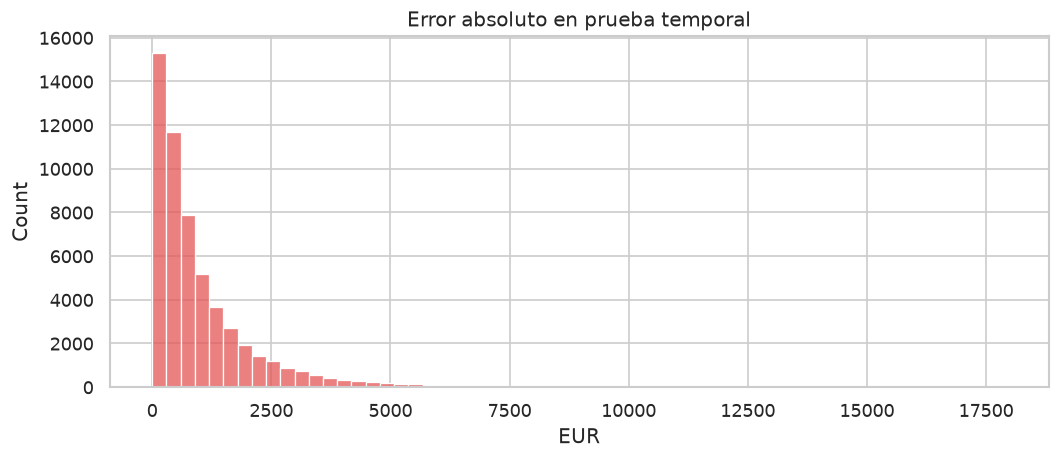

In [12]:
test_results = test[["Price", "Brand", "NotRepaired"]].copy()
test_results["prediction"] = model_pred
test_results["absolute_error"] = (test_results["Price"] - test_results["prediction"]).abs()
test_results["PriceBand"] = pd.cut(test_results["Price"], [0, 1000, 5000, 10000, np.inf], include_lowest=True)

def error_by(column, minimum=100):
    result = test_results.groupby(column, dropna=False, observed=True).agg(n=("Price", "size"), MAE_EUR=("absolute_error", "mean"), sesgo_EUR=("prediction", lambda x: (x - test_results.loc[x.index, "Price"]).mean()))
    return result.loc[result["n"] >= minimum].sort_values("MAE_EUR", ascending=False)

display(error_by("PriceBand", minimum=100))
display(error_by("NotRepaired", minimum=100))
display(error_by("Brand", minimum=300))
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(test_results["absolute_error"], bins=60, ax=ax, color="#E45756")
ax.set(title="Error absoluto en prueba temporal", xlabel="EUR")
plt.tight_layout(); plt.show()

## 12. Escenario condicionado para la decisión

**Pregunta.** ¿Cómo cambia la estimación del modelo para un perfil de referencia si se cambia el estado de reparación?  
**Procedimiento.** Se fija un perfil de referencia con medianas/modas del entrenamiento y se calculan dos predicciones cambiando sólo `NotRepaired`.  
**Resultado e implicación.** Esto ilustra una salida posible de la app y hace visible la dependencia del modelo respecto de sus entradas. No estima el retorno de reparar: el estado de reparación no fue asignado aleatoriamente y faltan costes, capacidad, condición previa y variables no observadas.

In [13]:
scenario = pd.DataFrame([{column: (X_train[column].median() if column in numeric_features else X_train[column].mode(dropna=True).iat[0]) for column in model_features}])
scenario_yes = scenario.copy(); scenario_yes["NotRepaired"] = "yes"
scenario_no = scenario.copy(); scenario_no["NotRepaired"] = "no"
scenario_ready = preprocessor.transform(pd.concat([scenario_yes, scenario_no], ignore_index=True))
scenario_pred = model.predict(scenario_ready)
scenario_result = pd.DataFrame({
    "escenario": ["perfil de referencia; NotRepaired=yes", "perfil de referencia; NotRepaired=no"],
    "precio_estimado_EUR": scenario_pred,
})
display(scenario)
display(scenario_result)
print("Uso permitido: comparar estimaciones condicionadas. Uso no permitido: concluir que cambiar la reparación causará la diferencia estimada o que la reparación es rentable.")

,AgeAtCrawl,PowerForAnalysis,Mileage,RegistrationMonthForAnalysis,VehicleType,Gearbox,Model,FuelType,Brand,NotRepaired
0,13.00,110.00,"150,000.00",6.00,sedan,manual,golf,petrol,volkswagen,no


,escenario,precio_estimado_EUR
0,perfil de referencia; NotRepaired=yes,"2,040.20"
1,perfil de referencia; NotRepaired=no,"3,082.75"


Uso permitido: comparar estimaciones condicionadas. Uso no permitido: concluir que cambiar la reparación causará la diferencia estimada o que la reparación es rentable.


## 13. Síntesis, límites y transición al MVP

### Evidencia obtenida

- **Descriptiva:** el inventario, los faltantes, los duplicados exactos, los dominios cuestionables, segmentos y cobertura temporal quedan documentados y recalculables.
- **Diagnóstica:** los registros inválidos y faltantes no se eliminan automáticamente; `LastSeen`, fechas de perfil y falta de ID estable son riesgos relevantes para el uso predictivo.
- **Predictiva:** la tabla de evaluación compara una baseline y un modelo de referencia en una prueba temporal. Sus métricas y tiempos son evidencia de esta ejecución, no un compromiso de producción.
- **Escenario:** la tabla final muestra predicciones condicionadas de un perfil de referencia, sin afirmar efecto causal ni rentabilidad de reparar.

### Decisiones pendientes antes del MVP

1. Confirmar el significado operativo de `Price`, población, momento exacto de cotización y variables disponibles entonces.
2. Acordar MAE/RMSE objetivo, cobertura mínima, latencia máxima, presupuesto de entrenamiento, hardware y frecuencia de reentrenamiento.
3. Resolver republicaciones con un identificador estable y obtener origen/muestreo, historial de ventas y datos de equipamiento si deben formar parte del producto.
4. Definir políticas de calidad e imputación por segmento y una evaluación prospectiva antes de operar.
5. Para recomendaciones prescriptivas, incorporar alternativas de acción, costes, restricciones y evidencia causal o experimental.

### Reproducibilidad

Desde la raíz: `UV_CACHE_DIR=/tmp/rusty-bargain-uv-cache uv sync`; instale el kernel con `uv run python -m ipykernel install --user --name rusty-baregain-mvp --display-name 'Python (Rusty_Baregain_mvp)'`; ejecute `uv run jupyter execute notebooks/analisis_integral_rusty_baregain.ipynb --inplace --kernel_name rusty-baregain-mvp`. Las rutas son robustas si el notebook se abre desde la raíz o `notebooks/`.